In [2]:
from antares_devkit.models import BaseFilter
from antares_devkit.models import DevKitLocus
from antares_client import search
import numpy as np
import matplotlib.pyplot as plt
from astropy.time import Time
import pandas as pd
import math
from astropy.coordinates import Angle, SkyCoord
import astropy.units as u

t_now = Time.now().mjd

In [63]:
#extract data from lsst alert
def lsst_alert(alert):
    obs_date = float(alert.properties['lsst_diaSource_midpointMjdTai'])
    oid_mag = float(-2.5*np.log10(alert.properties['lsst_diaSource_scienceFlux']) + 31.4)
    temp_mag = float(-2.5*np.log10(alert.properties['lsst_diaSource_templateFlux']) + 31.4)
    diff_mag = float(temp_mag - oid_mag)
    snr = float(alert.properties['lsst_diaSource_snr'])
    
    bandpass = alert.properties['lsst_diaSource_band']
    band = 'lsst_' + str(bandpass)

    if alert.properties['lsst_diaSource_isNegative'] == True:
        pos_or_neg = -1
    else:
        pos_or_neg = 1
        
    return {band: [obs_date, oid_mag, temp_mag, diff_mag, pos_or_neg, snr]}

def lsst_quality(alert):
    quality = True
    quality &= alert.properties['lsst_diaSource_reliability'] >= 0.6
    quality &= alert.properties['lsst_diaSource_psfFlux_flag'] == False
    quality &= alert.properties['lsst_diaSource_centroid_flag'] == False
    quality &= alert.properties['lsst_diaSource_shape_flag'] == False
    quality &= alert.properties['lsst_diaSource_isDipole'] == False
    quality &= alert.properties['lsst_diaSource_pixelFlags_saturated'] == False
    quality &= alert.properties['lsst_diaSource_pixelFlags_edge'] == False
    quality &= alert.properties['lsst_diaSource_pixelFlags_cr'] == False
    quality &= alert.properties['lsst_diaSource_pixelFlags_streak'] == False

    if 'lsst_diaSource_ssObjectId' in alert.properties:
        quality &= alert.properties['lsst_diaSource_ssObjectId'] in (0, None, "0")
    return quality

#extract data from ztf alert
#uses formula from 260609 6/15 markdown cell
def ztf_alert(alert):
    bands = ['x', 'g', 'R', 'i']
    
    band_id = alert.properties['ztf_fid']
    obs_date = float(alert.properties['ant_mjd'])
    ant_mag = alert.properties['ant_mag']
    temp_mag = alert.properties['ztf_magnr']
    diff_img_mag = alert.properties['ztf_magpsf']
    
    if alert.properties['ztf_isdiffpos'] == 'f' or alert.properties['ztf_isdiffpos'] == 0:
        diff_mag = -2.5* np.log10(1 - 10.**(0.4*(temp_mag - diff_img_mag)))
        pos_or_neg = -1
    else:
        diff_mag = -2.5* np.log10(10.**(0.4*(temp_mag - diff_img_mag)) + 1)
        pos_or_neg = 1

    oid_mag = diff_mag + temp_mag
    oid_snr = float(1.0857 / alert.properties['ztf_sigmapsf'])

    band = 'ztf_' + str(bands[band_id])
    return {band: [obs_date, oid_mag, temp_mag, diff_mag, pos_or_neg, oid_snr]}

#checks ztf alert for good quality
def ztf_quality(alert):
    quality = True
    quality &= alert.properties['ztf_rb'] >= 0.65
    quality &= alert.properties['ztf_nbad'] == 0
    quality &= alert.properties['ztf_fwhm'] <= 5
    quality &= alert.properties['ztf_elong'] <= 1.2
    quality &= abs(alert.properties['ztf_magdiff']) <= 0.1
    return quality

#unpacks all alerts (that pass a quality test)
def oid_get_info(alerts):
    oid = {'lsst_g': 0, 'lsst_r': 0, 'lsst_i': 0, 'lsst_z': 0, 'lsst_u': 0, 'lsst_y': 0, 
               'ztf_g': 0, 'ztf_R': 0, 'ztf_i': 0}
    
    for alert in alerts:
        if alert.properties['ant_survey'] == 4:
            lsst_pass = lsst_quality(alert)
            if lsst_pass == True:
                comp = lsst_alert(alert)
            else:
                continue
        elif alert.properties['ant_survey'] == 1:
            ztf_pass = ztf_quality(alert)
            if ztf_pass == True:
                comp = ztf_alert(alert)
            else:
                continue
        else:
            continue
            
        band = [*comp][0]
        
        if oid[band] == 0:
            oid_df = pd.DataFrame([comp[band]], columns = ['mjd', 'oid_mag', 'template_mag', 'diff_mag', 'pos/neg', 'snr'])
            oid[band] = {'data': oid_df}
            continue
        else:
            data_df = pd.DataFrame([comp[band]], columns = ['mjd', 'oid_mag', 'template_mag', 'diff_mag', 'pos/neg', 'snr'])
            current_data = oid[band]['data']
            oid[band]['data'] = pd.concat([current_data, data_df]).drop_duplicates().reset_index(drop=True)
    return oid

#get latest mjd for an oid
def get_latest_mjd(oid):
    latest_mjd = 0
    for band in oid:
        if band == 'locus':
            continue
        if oid[band] == 0:
            continue
            
        if latest_mjd < oid[band]['data']['mjd'].iloc[-1]:
            latest_mjd = oid[band]['data']['mjd'].iloc[-1]
    return latest_mjd

#get earliest mjd for an oid
def get_earliest_mjd(oid):
    earliest_mjd = 1000000
    for band in oid:
        if oid[band] == 0:
            continue
        if earliest_mjd > oid[band]['data']['mjd'].iloc[0]:
            earliest_mjd = oid[band]['data']['mjd'].iloc[0]
    return earliest_mjd

#check if oid passes variance threshold
def var_check(locus, day_lim, var_thresh):
    check = 0
    oid = oid_get_info(locus.alerts)
    latest_mjd = get_latest_mjd(oid)
    for band in oid:
        if oid[band] == 0:
            continue

        recent_obs = oid[band]['data'][oid[band]['data']['mjd'] >= float(latest_mjd) - day_lim].index.tolist()

        if len(recent_obs) > 2: #if +3 alerts w/in day_lim of latest_mjd, then we look at the variance + hyper_v (only including alerts w/in time frame)
            temp_var = float(np.var(oid[band]['data']['template_mag']))
            if temp_var >= 0.01:
                continue
            
            here_var = float(np.var(oid[band]['data']['oid_mag'][recent_obs[0]:]))
            here_diffs = float(np.median(oid[band]['data']['diff_mag'][recent_obs[0]:]))  
            oid[band]['variance'] = here_var
            
            if here_var > 0:
                var_diff = float(here_diffs/here_var)
                oid[band]['var_diff_rat'] = var_diff
        
            if here_var >= var_thresh:
                check += 1

    if check > 0:
        return oid

#check is oid passes difference threshold
def diff_check(locus, day_lim, diff_thresh):
    check = 0
    oid = oid_get_info(locus.alerts)
    latest_mjd = get_latest_mjd(oid)
    for band in oid:
        if oid[band] == 0:
            continue

        recent_obs = oid[band]['data'][oid[band]['data']['mjd'] >= float(latest_mjd) - day_lim].index.tolist()

        if len(recent_obs) > 2: #if +3 alerts w/in day_lim of latest_mjd, then we look at the variance + hyper_v (only including alerts w/in time frame)
            temp_var = float(np.var(oid[band]['data']['template_mag']))
            if temp_var >= 0.01:
                continue

            here_diffs = float(np.median(oid[band]['data']['diff_mag'][recent_obs[0]:])) 
            oid[band]['diff_med'] = here_diffs

            if here_diffs >= diff_thresh:
                check += 1

    if check > 0:
        return oid

#check is oid passes snr threshold
def snr_check(oid, day_lim, snr_thresh):
    check = 0
    # oid = oid_get_info(locus.alerts)
    latest_mjd = get_latest_mjd(oid)
    for band in oid:
        if band == 'locus':
            continue
        elif oid[band] == 0:
            continue

        recent_obs = oid[band]['data'][oid[band]['data']['mjd'] >= float(latest_mjd) - day_lim].index.tolist()

        if len(recent_obs) > 2: #if +3 alerts w/in day_lim of latest_mjd, then we look at the variance + hyper_v (only including alerts w/in time frame)
            temp_var = float(np.var(oid[band]['data']['template_mag']))
            if temp_var >= 0.01:
                continue

            here_snrs = float(np.median(oid[band]['data']['snr'][recent_obs[0]:])) 
            oid[band]['snr_med'] = here_snrs

            if here_snrs >= snr_thresh:
                check += 1

    if check > 0:
        return oid

def moving_window_var(oid, day_lim):
    passes = {'lsst_g': 0, 'lsst_r': 0, 'lsst_i': 0, 'lsst_z': 0, 'lsst_u': 0, 'lsst_y': 0, 
               'ztf_g': 0, 'ztf_R': 0, 'ztf_i': 0}
    for band in oid:
        if band == 'locus':
            continue
        if oid[band] == 0:
            continue
            
        here_data = []
        for i in np.arange(0, len(oid[band]['data']), 1):
            mjd = float(oid[band]['data']['mjd'][i])
            oid_mag = float(oid[band]['data']['oid_mag'][i])
            diff_mag = float(oid[band]['data']['template_mag'][i]-oid[band]['data']['oid_mag'][i])
            
            if i < 2:
                here_data = [[mjd, oid_mag, diff_mag, 0, 0, 0, 0]]
            else:
                night = float(mjd - oid[band]['data']['mjd'][0])
                med_diff = float(np.median(oid[band]['data']['template_mag'][:i]-oid[band]['data']['oid_mag'][:i]))
                var = float(np.var(oid[band]['data']['oid_mag'][:i]))
                hyper_v = float(np.sqrt(med_diff**2 + (4*var)**2))
                j = 1
                day_lim_var = 0
                while day_lim > (oid[band]['data']['mjd'][i] - oid[band]['data']['mjd'][i-j]):
                    day_lim_var = float(np.var(oid[band]['data']['oid_mag'][i-j:i]))
                    if j < i:
                        j += 1
                    else:
                        break
                
                here_data.append([mjd, oid_mag, diff_mag, med_diff, var, hyper_v, day_lim_var])
        here_df = pd.DataFrame(np.array(here_data), columns = ['mjd', 'oid_mag', 'diff_mag', 'med_diff', 'var', 'hyper_v', 'var_20'])
        passes[band] = here_df

    return passes

In [4]:
mag_max = 21
# mag_min = 17

q_lsst_magcut = {
    "query": {
        "bool": {
            "filter": [
                { "range": { "properties.newest_alert_magnitude": { "lte": mag_max} } },
                { "exists": { "field": "properties.survey.lsst" } },
                { "range": { "properties.newest_alert_observation_time": { "gte": 61234} } }
                  ]
        }
    }
}

loci = []
oids_sample = {}
# oids_var[0.4] = {}
checked = 0
for locus in search.search(q_lsst_magcut):
    oid_dv = locus.to_devkit()
    oid_locus = DevKitLocus.model_validate(oid_dv)

    oid_here = oid_get_info(oid_locus.alerts)
    oid_here['locus'] = locus
    oids_sample[oid_dv['id']] = oid_here
    # loci.append(oid_locus)
    
    # high_var_oid = oid_var_check(oid_locus.alerts, 20, 0.4)

    # if high_var_oid == None:
    #     continue

    # oids_var[0.4][oid_dv['id']]= high_var_oid
    checked += 1
    if len(oids_sample) >= 8000:
        break

/var/folders/ym/gbj1z46s0wg5zdmkkq0xpptr0000gs/T/ipykernel_87813/831482088.py:47: RuntimeWarning: invalid value encountered in log10
  diff_mag = -2.5* np.log10(1 - 10.**(0.4*(temp_mag - diff_img_mag)))


ConnectTimeout: HTTPSConnectionPool(host='api.antares.noirlab.edu', port=443): Max retries exceeded with url: /v1/loci/ANT2020bkr5y/alerts (Caused by ConnectTimeoutError(<urllib3.connection.HTTPSConnection object at 0x69f5f4cd0>, 'Connection to api.antares.noirlab.edu timed out. (connect timeout=60)'))

In [5]:
print(checked, len(oids_sample))

4192 3775


In [16]:
#putting the sample thru a snr cut
#then through the window checker
oids_window = {}
for oid_id in oids_sample:
    snr_pass = snr_check(oids_sample[oid_id], 20, 10)
    if snr_pass is None:
        continue
    window_pass = moving_window_var(snr_pass, 20)
    oids_window[oid_id] = window_pass

In [17]:
len(oids_window)

1653

/var/folders/ym/gbj1z46s0wg5zdmkkq0xpptr0000gs/T/ipykernel_18369/470633732.py:5: RuntimeWarning: More than 20 figures have been opened. Figures created through the pyplot interface (`matplotlib.pyplot.figure`) are retained until explicitly closed and may consume too much memory. (To control this warning, see the rcParam `figure.max_open_warning`). Consider using `matplotlib.pyplot.close()`.
  fig, ax = plt.subplots(2, 1, figsize=(8,6), sharex=True)


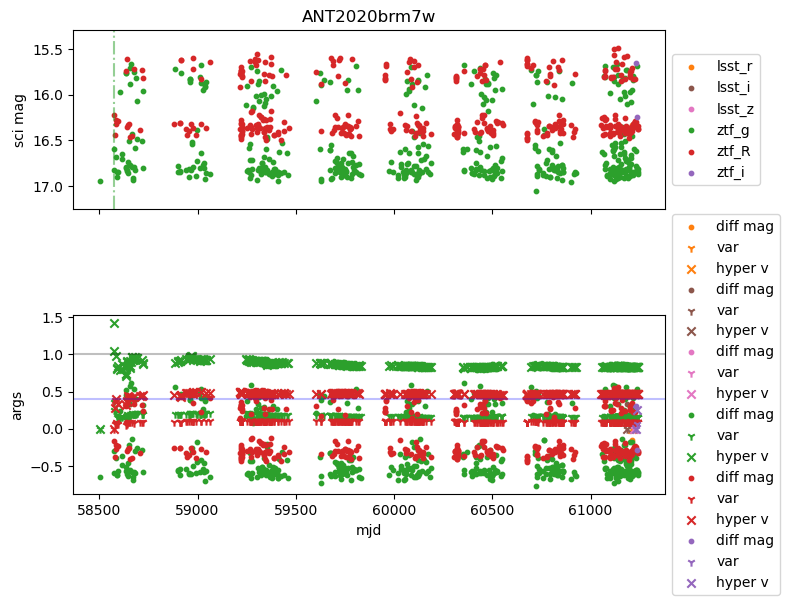

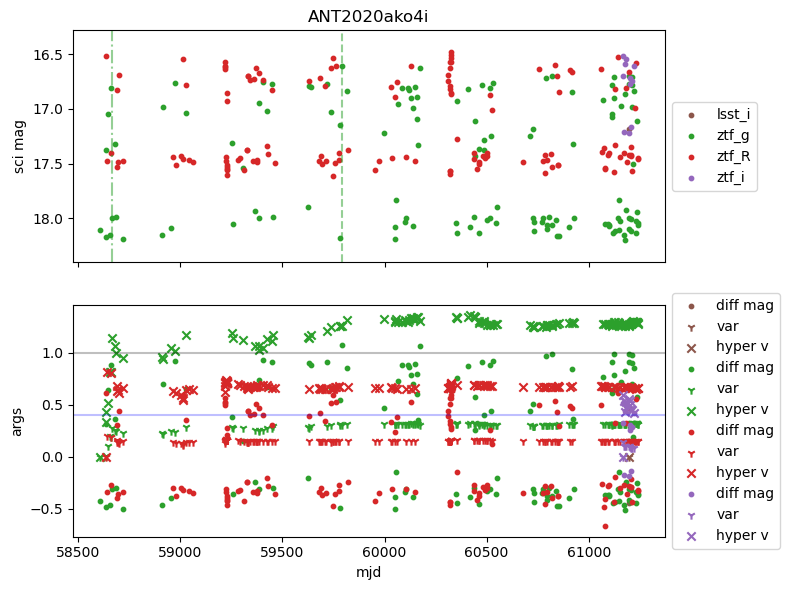

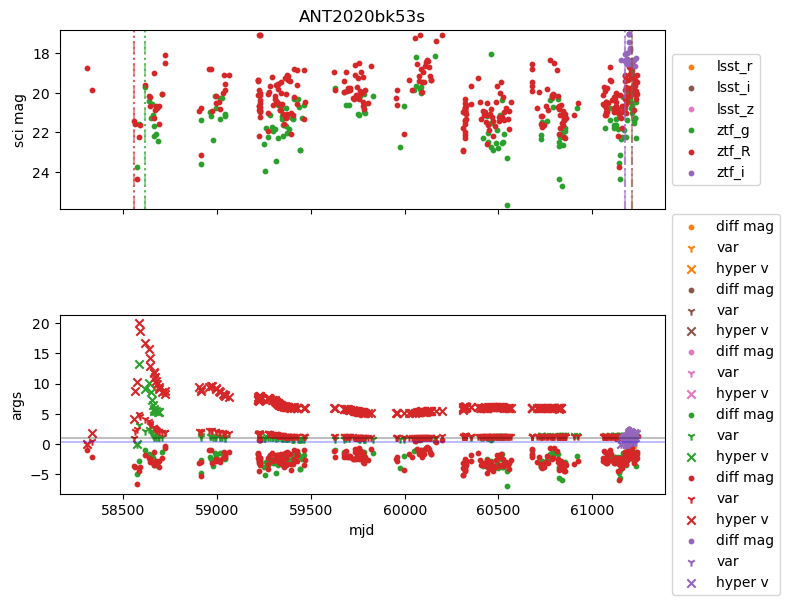

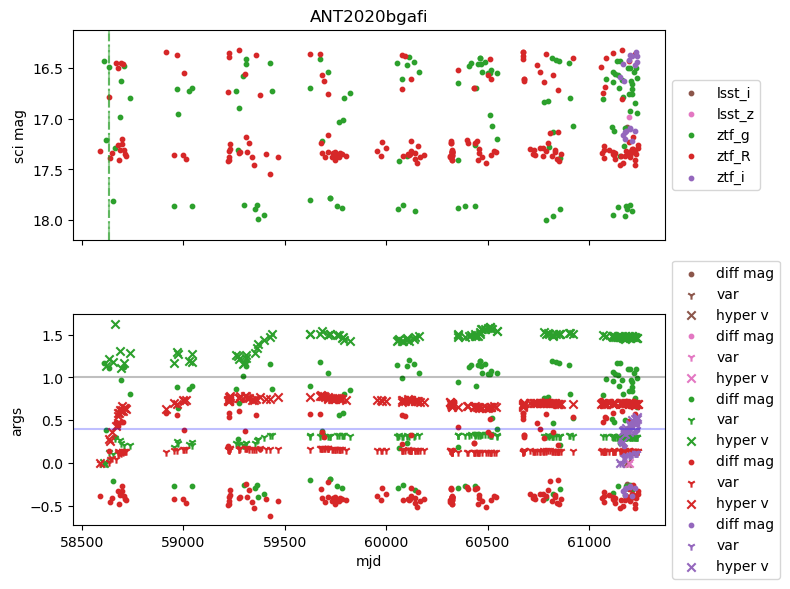

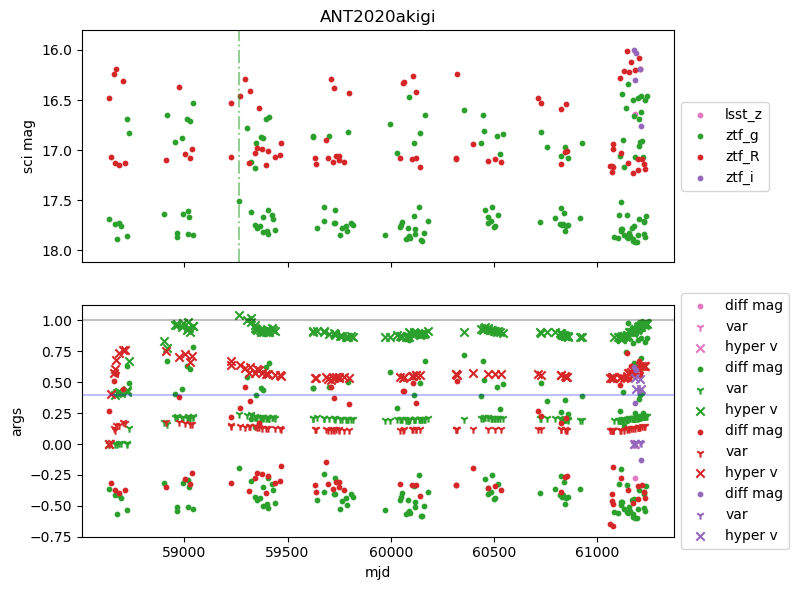

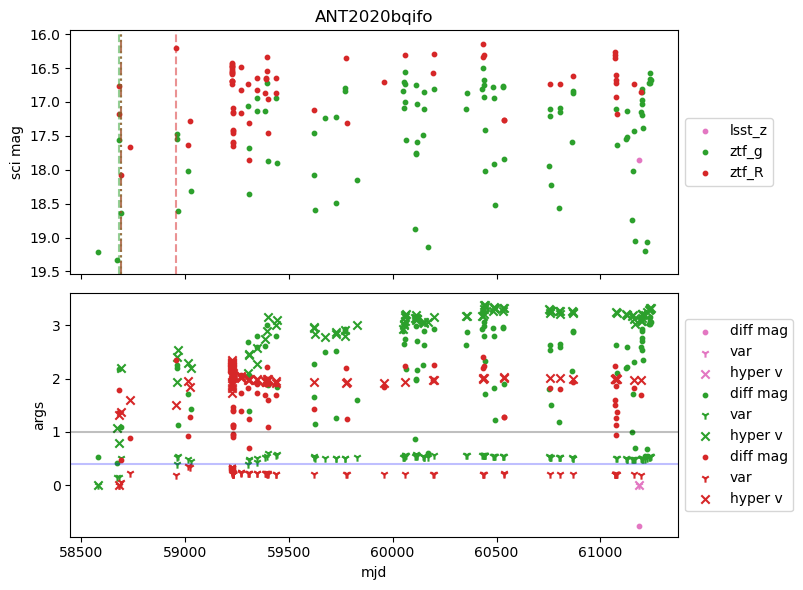

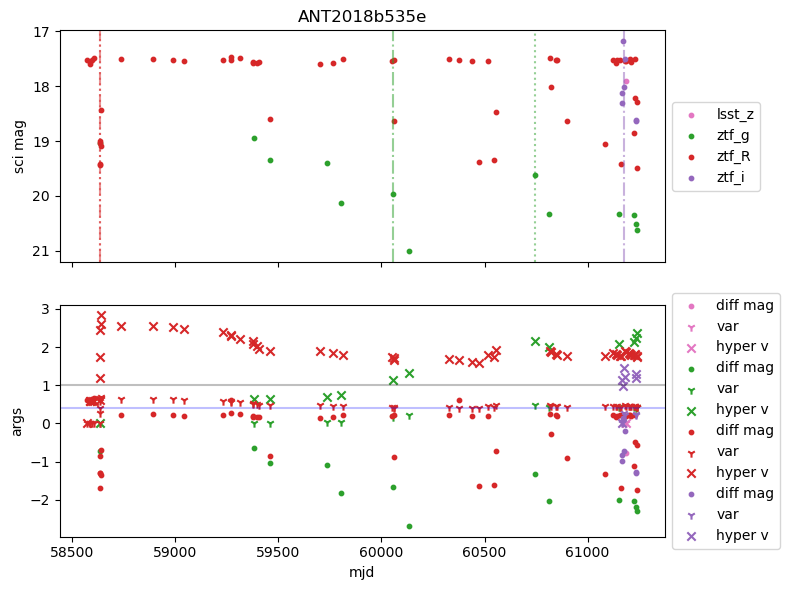

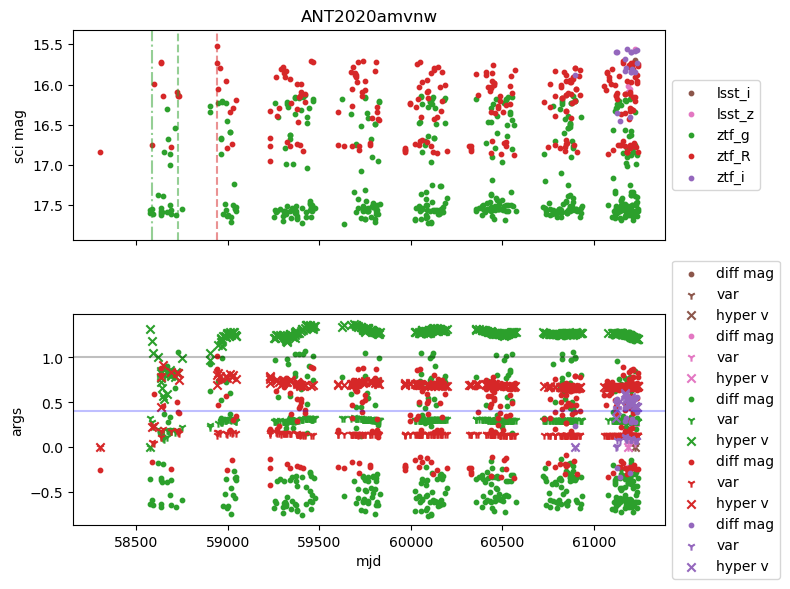

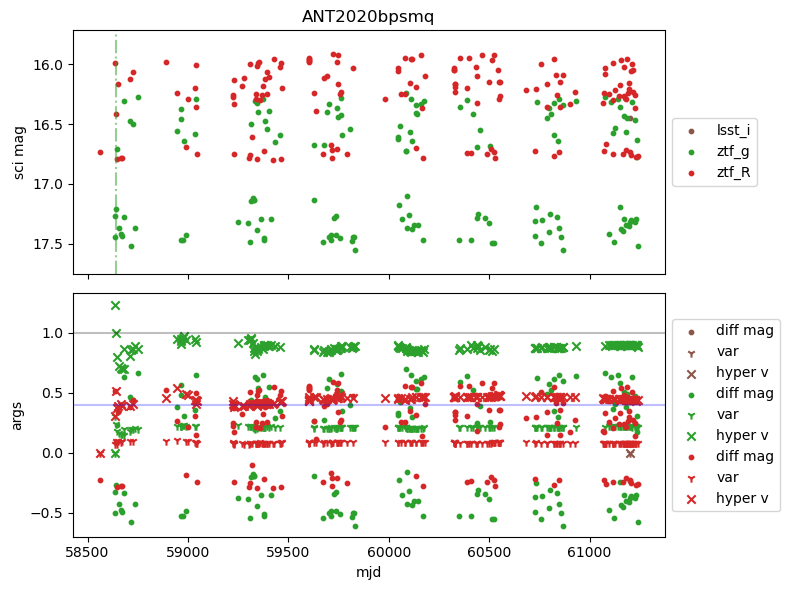

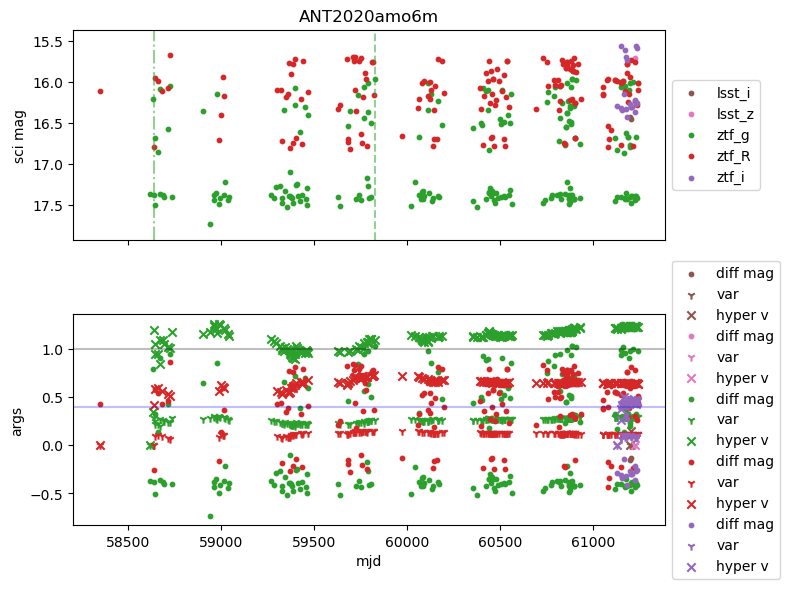

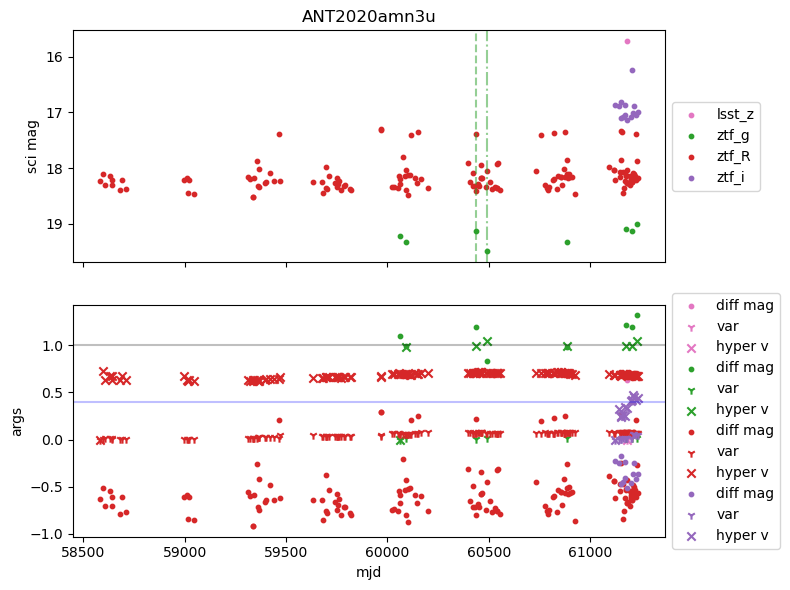

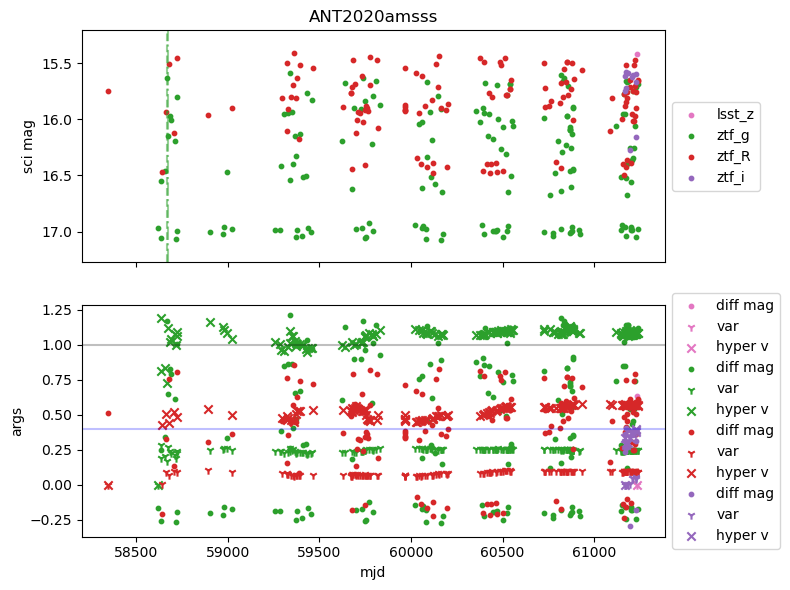

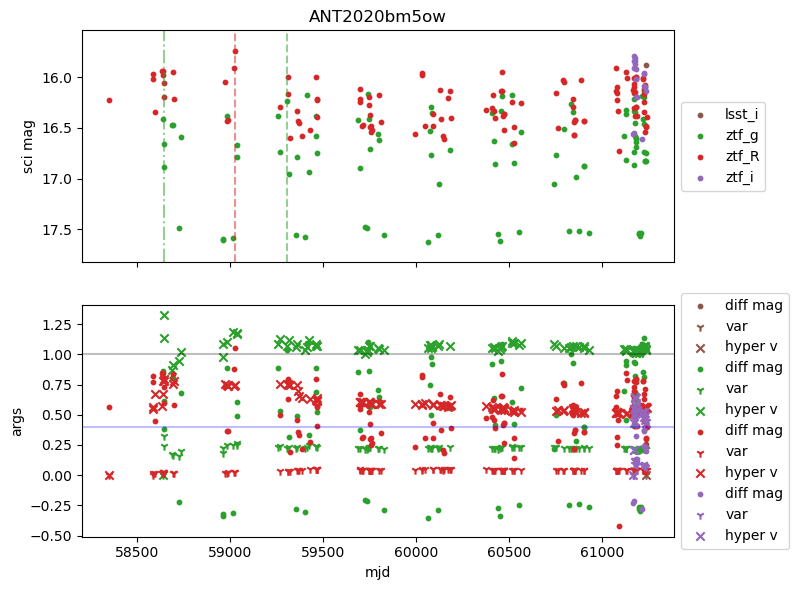

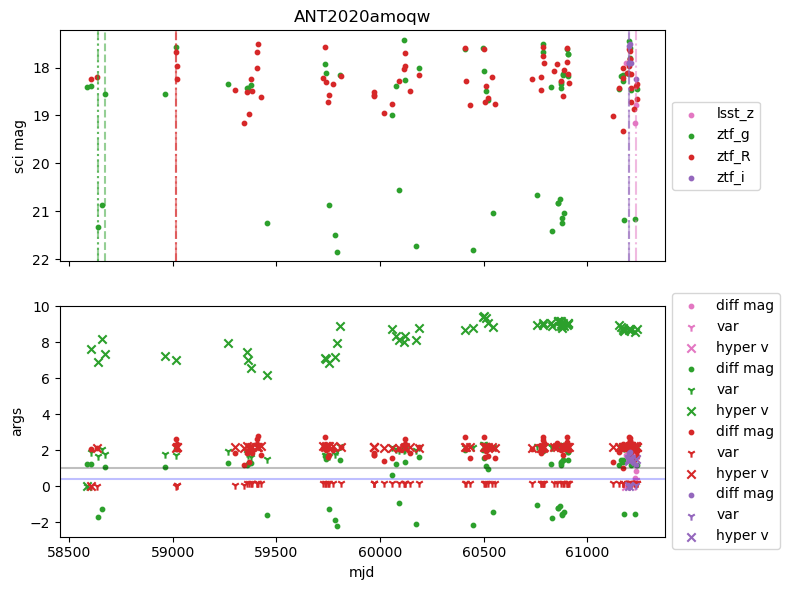

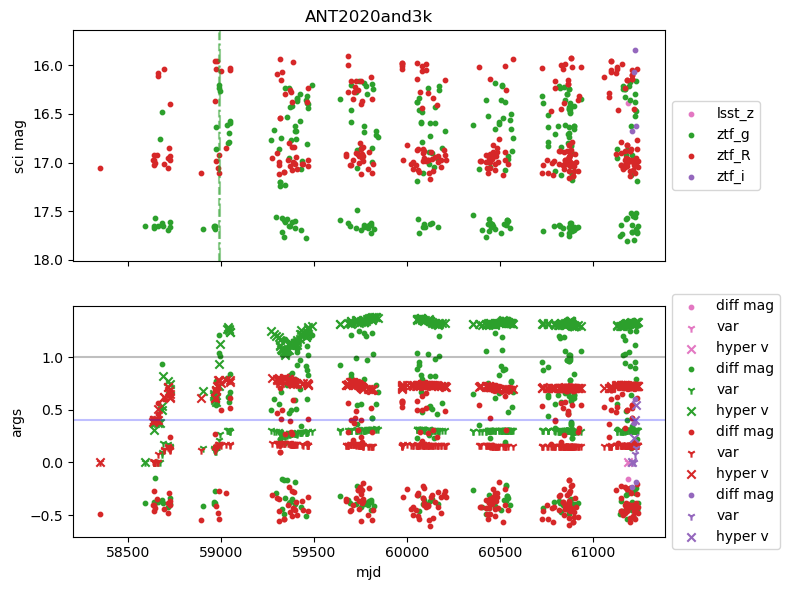

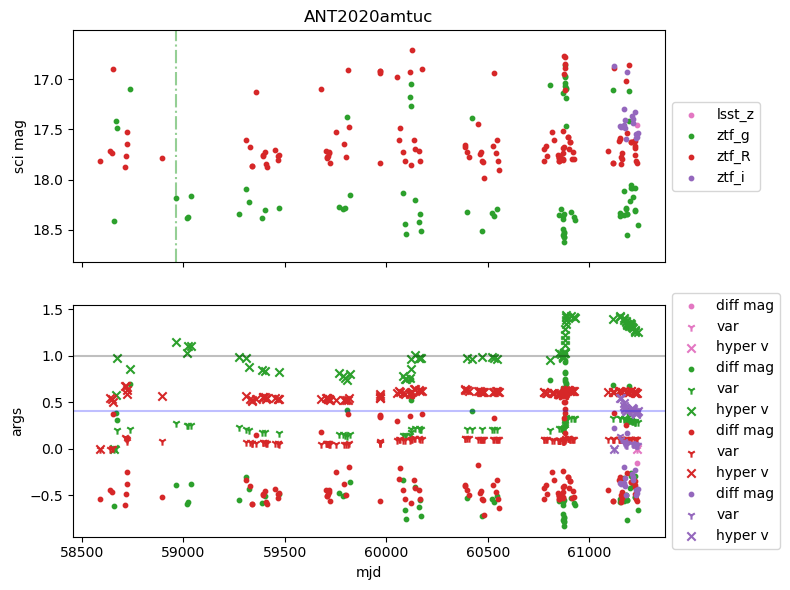

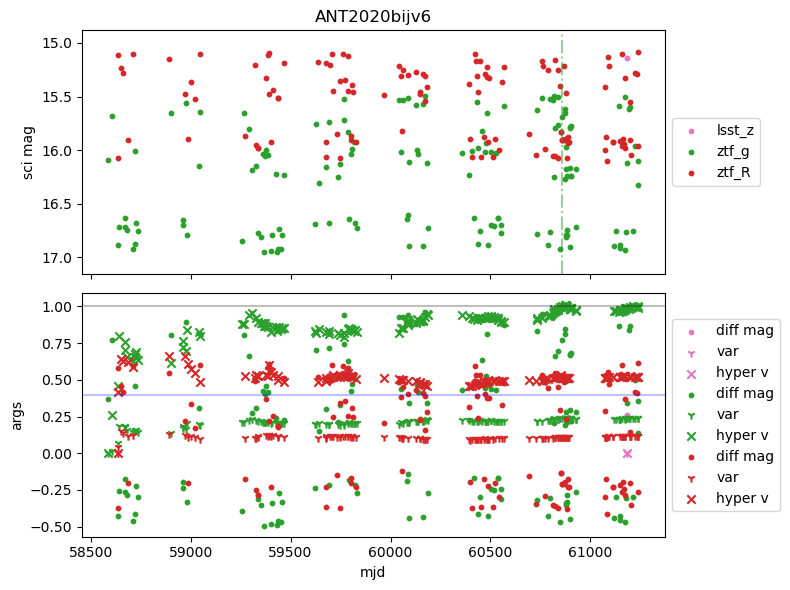

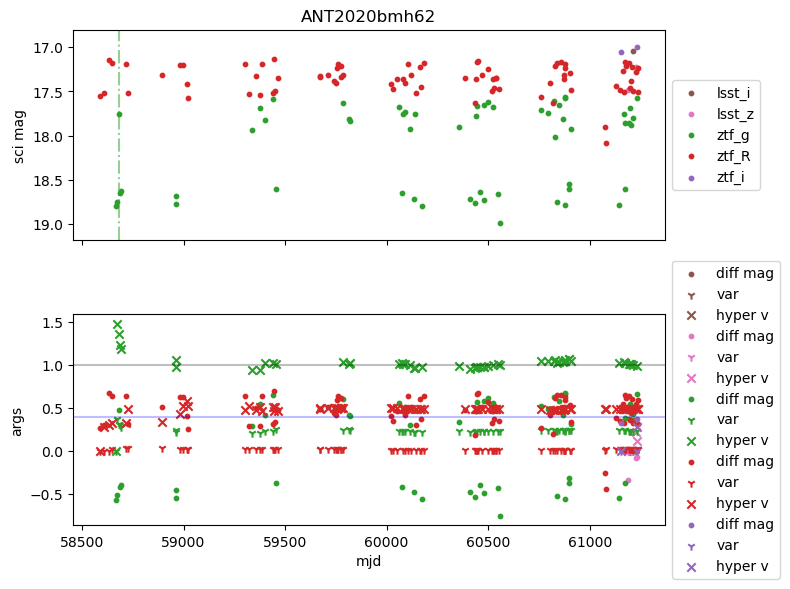

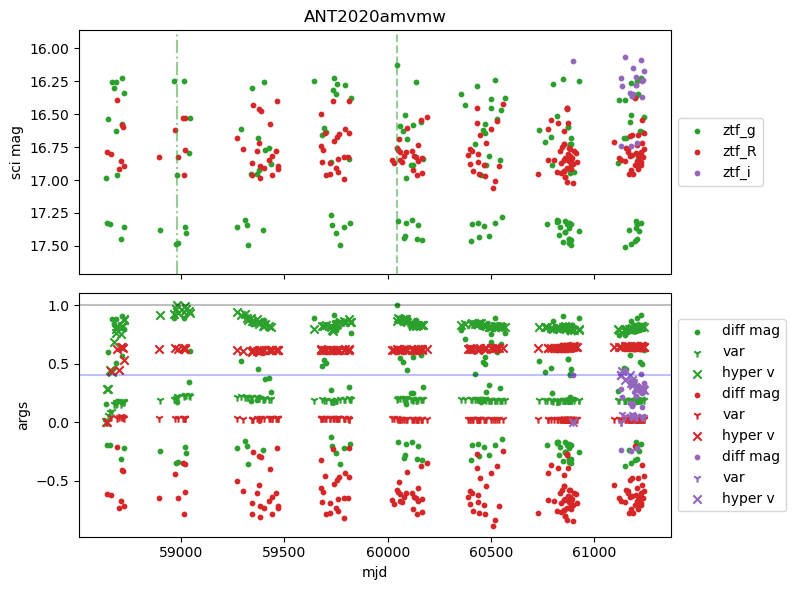

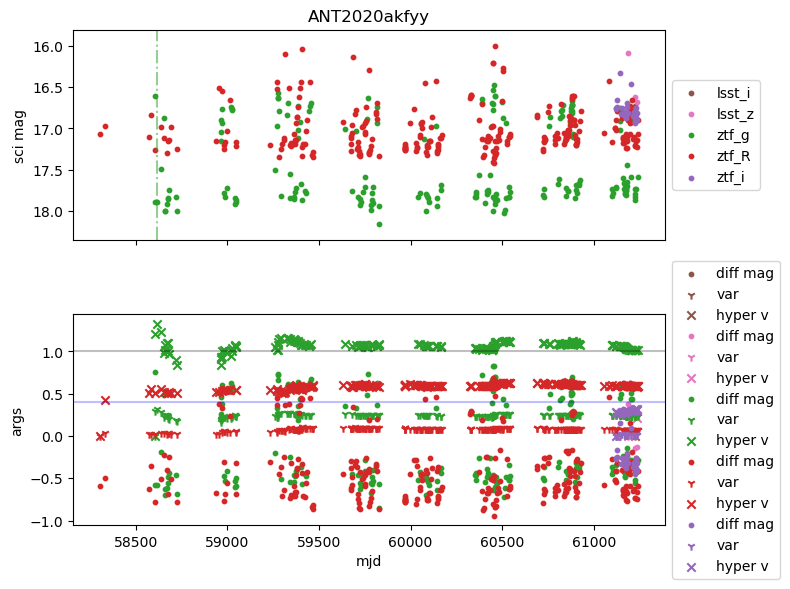

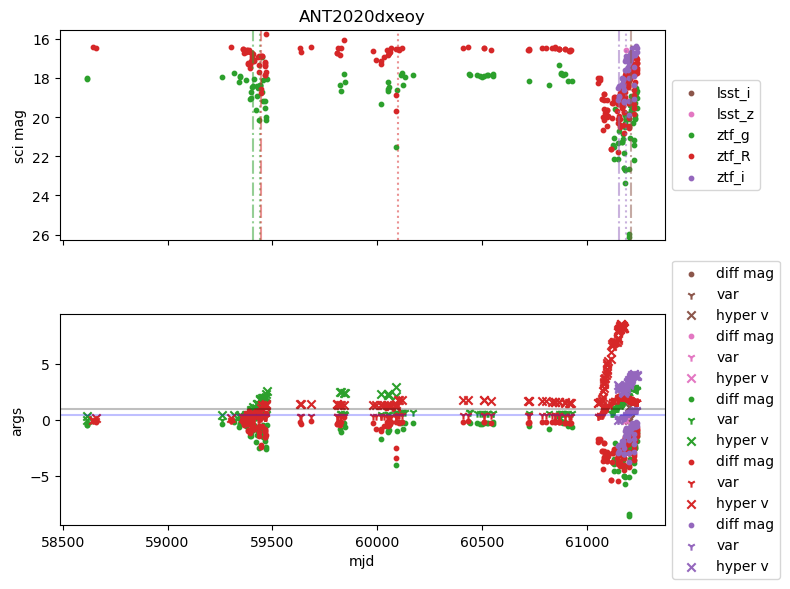

In [25]:
colors = {'lsst_g': 'tab:blue', 'lsst_r': 'tab:orange', 'lsst_i': 'tab:brown', 'lsst_z': 'tab:pink', 'lsst_u': 'tab:olive', 
          'lsst_y': 'tab:cyan' ,'ztf_g': 'tab:green', 'ztf_R': 'tab:red', 'ztf_i': 'tab:purple'}
i = 0
for key in oids_window:
    fig, ax = plt.subplots(2, 1, figsize=(8,6), sharex=True)
    max_mags = []
    min_mags = []
    check = 0
    for band in oids_window[key]:
        if isinstance(oids_window[key][band], pd.DataFrame) == 0:
            continue

        max_mags.append(max(oids_window[key][band]['oid_mag']))
        min_mags.append(min(oids_window[key][band]['oid_mag']))

        # ax[0].plot(sample_windows[key][band]['mjd'], sample_windows[key][band]['oid_mag'], label=band, color=colors[band])
        ax[0].scatter(oids_window[key][band]['mjd'], oids_window[key][band]['oid_mag'], label=band, s=10, color=colors[band])
        # ax[1].plot(sample_windows[key][band]['mjd'], sample_windows[key][band]['diff_mag'], color=colors[band])
        ax[1].scatter(oids_window[key][band]['mjd'], oids_window[key][band]['diff_mag'], s=10, label='diff mag', color=colors[band])
        ax[1].scatter(oids_window[key][band]['mjd'], oids_window[key][band]['var'], marker='1', label='var', color=colors[band])
        ax[1].scatter(oids_window[key][band]['mjd'], oids_window[key][band]['hyper_v'], marker='x', label='hyper v', color=colors[band])
        # ax[1].scatter(sample_windows[key][band]['mjd'], sample_windows[key][band]['var_20'], marker='*', label='var 20', color=colors[band])

        trig_diff_mag = oids_window[key][band]['diff_mag'][2:] > 1
        if trig_diff_mag.sum() > 0:
            check +=1
            trig_dmi = list(trig_diff_mag).index(True) + 2
            ax[0].axvline(oids_window[key][band]['mjd'][trig_dmi], 0, 2.5, ls='--', c=colors[band], alpha=0.5)
        
        trig_var = oids_window[key][band]['var'][2:] > 0.4
        if trig_var.sum() > 0:
            check +=1
            trig_vari = list(trig_var).index(True) + 2
            ax[0].axvline(oids_window[key][band]['mjd'][trig_vari], 0, 2.5, ls=':', c=colors[band], alpha=0.5)
            
        trig_hyperv = oids_window[key][band]['hyper_v'][2:] > 1
        if trig_hyperv.sum() > 0:
            check +=1
            trig_hypervi = list(trig_hyperv).index(True) + 2
            ax[0].axvline(oids_window[key][band]['mjd'][trig_hypervi], 0, 2.5, ls='-.', c=colors[band], alpha=0.5)

    if check == 0:
        plt.close()
        continue
        
    ax[0].set_ylim([max(max_mags)+0.2, min(min_mags)-0.2])
    ax[0].legend(loc='center left', bbox_to_anchor=(1, 0.5))
    ax[1].legend(loc='center left', bbox_to_anchor=(1, 0.5))
    ax[1].axhline(y=1, c='k', alpha=0.25)
    ax[1].axhline(y=0.4, c='b', alpha=0.25)
    
    ax[0].set_title(key)
    ax[0].set_ylabel('sci mag')
    ax[1].set_ylabel('args')
    ax[1].set_xlabel('mjd')
    plt.tight_layout()

    i+= 1
    if i > 20:
        break

looking at the lightcurves that pass the current thresholds of hyperv >1, diff_mag >1, and var > 0.4, i feel like there is a lot of impurity from general variability, but im not sure if thats what i want? i said that i wanted to observe things that changed a lot but now im feeling like i want to focus on things like tdes, cvs, and clagns. i think that im kinda losing track of the original goal. 

well, i want to exclude things that come from known variable stars. i am going to try to do survey matching with the [General Catalog of Variable Stars (GCVS)](https://heasarc.gsfc.nasa.gov/w3browse/all/gcvs.html) to remove and objects that match with a known variable star. for now, this is what it will be, but in the future i want to include smth that doesn allow these to pass if smth particularly interesting is happening (again, thinking of the possibility of a variable star to be involved in smth like a TDE of CV)

In [46]:
passed = {'diff_mag': 0, 'hyper_v': 0, 'var': 0}
for key in oids_window:
    passed_here = {'diff_mag': 0, 'hyper_v': 0, 'var': 0}
    for band in oids_window[key]:
        if isinstance(oids_window[key][band], pd.DataFrame) == 0:
            continue
        if oids_window[key][band]['diff_mag'][-1] > 1:
            passed_here['diff_mag'] += 1
        if oids_window[key][band]['hyper_v'][-1] > 1:
            passed_here['hyper_v'] += 1
        if oids_window[key][band]['var'][-1] > 0.4:
            passed_here['var'] += 1
    for param in passed_here:
        if passed_here[param] > 0:
            passed[param] += 1

KeyError: -1

In [44]:
passed

{'diff_mag': 192, 'hyper_v': 510, 'var': 93}

In [33]:
len(oids_window)

3151

### Classification Flags

| Flag | Catalogs / Columns | Criterion |
|---|---|---|
| `known_star` | `asassn_variable_catalog`<br>`asassn_variable_catalog_v2_20190802`<br>`sdss_stars` | Any positional cross-match |
| `known_agn` | `veron_agn_qso`<br>`milliquas` | Any positional cross-match |
| `known_galaxy` | `2mass_xsc`, `nyu_valueadded_gals`<br>`sdss_gals`, `RC3` | Any positional cross-match |
| `gaia_likely_star` | `gaia_dr3_gaia_source` | $\texttt{classprob\_dsc\_combmod\_star} > 0.5$ ([Delchambre et al. 2023](https://ui.adsabs.harvard.edu/abs/2023A%26A...674A..31D/abstract)) |
| `gaia_astro_star` | `gaia_dr3_gaia_source` | $(\texttt{parallax} + 0.017) / \texttt{parallax\_error} > 5$ or $\text{pm} > 5$‡ ([Carnerero et al. 2023](https://ui.adsabs.harvard.edu/abs/2023A%26A...674A..24C/abstract)) |
| `ps1_pointlike` | `ztf_sgscore{1,2,3}`<br>`ztf_distpsnr{1,2,3}` | Any PS1 neighbor within 1″ with sgscore $> 0.5$ |

‡The proper motion significance is the Mahalanobis distance $\text{pm} = \sqrt{(\alpha^2 + \beta^2 - 2\alpha\beta\gamma)/(1-\gamma^2)}$, where $\alpha = \texttt{pmra}/\texttt{pmra\_error}$, $\beta  = \texttt{pmdec}/\texttt{pmdec\_error}$, and $\gamma = \texttt{pmra\_pmdec\_corr}$ is the $\texttt{pmra}-\texttt{pmdec}$ correlation coefficient. The $0.017\,\text{mas}$ parallax offset corrects for the global Gaia EDR3 zero point.

In [65]:
oids_sample['ANT2020mte6q']['locus'].properties['newest_alert_observation_time']

61256.41703699995

In [68]:
oids_sample['ANT2020mte6q']['locus'].alerts[-1].properties['ant_mjd']

61256.41703699995

In [58]:
for key in oids_window:
    
    oids_window[key]['flags'] = {'known_star': False, 'known_agn': False, 'known_galaxy': False, 'gaia_likely_star': False, 
                            'gaia_astro_star': False, 'ps1_pointlike': False}
    for cat in oids_sample[key]['locus'].catalog_objects:
        if cat == 'asassn_variable_catalog' or cat == 'asassn_variable_Catalog_v2_20190802' or cat == 'sdss_stars':
            oids_window['flags']['known_star'] = True
        if cat == 'veron_agn_qso' or cat == 'milliquas':
            oids_window['flags']['known_agn'] = True
        if cat == '2mass_xsc' or cat == 'nyu_valueadded_gals' or cat == 'sdss_gals' or cat == 'RC3':
            oids_window['flags']['known_galaxy'] = True
        if cat == 'gaia_dr3_gaia_source':
            if isinstance(oids_sample[key]['locus'].catalog_objects[cat][0]['classprob_dsc_combmod_star'], float) == 1 and oids_sample[key]['locus'].catalog_objects[cat][0]['classprob_dsc_combmod_star'] > 0.5:
                oids_window['flags']['gaia_likely_star'] = True
            if isinstance(oids_sample[key]['locus'].catalog_objects[cat][0]['parallax'], float) == 1:
                gdr3_check1 = (oids_sample[key]['locus'].catalog_objects[cat][0]['parallax'] + 0.017)/oids_sample[key]['locus'].catalog_objects[cat][0]['parallax_error']
                alpha = oids_sample[key]['locus'].catalog_objects[cat][0]['pmra']/oids_sample[key]['locus'].catalog_objects[cat][0]['pmra_error']
                beta = oids_sample[key]['locus'].catalog_objects[cat][0]['pmdec']/oids_sample[key]['locus'].catalog_objects[cat][0]['pmdec_error']
                gamma = oids_sample[key]['locus'].catalog_objects[cat][0]['pmra_pmdec_corr']
                gdr3_check2 = np.sqrt((alpha**2 + beta**2 -2*alpha*beta*gamma)/(1 - gamma**2))
                if gdr3_check1 > 5 or gdr3_check2 > 5:
                    oids_window['flags']['gaia_astro_star'] = True
        alert_temp = oids_sample[key]['locus'].alerts[-1].properties
        if (alert_temp['ztf_sgscore1'] > 0.5 and alert_temp['ztf_distpsnr1'] < 1) or (alert_temp['ztf_sgscore2'] > 0.5 and alert_temp['ztf_distpsnr2'] < 1) or (alert_temp['ztf_sgscore3'] > 0.5 and alert_temp['ztf_distpsnr3'] < 1):
            oids_window['flags']['ps1_pointlike'] = True

KeyError: 'flags'

In [59]:
oids_window

{'ANT2019mdcsg': {'lsst_g': 0,
  'lsst_r': 0,
  'lsst_i':             mjd    oid_mag  diff_mag  med_diff  var  hyper_v  var_20
  0  61218.427719  18.375785  -0.24494       0.0  0.0      0.0     0.0,
  'lsst_z': 0,
  'lsst_u': 0,
  'lsst_y': 0,
  'ztf_g':               mjd    oid_mag  diff_mag  med_diff       var   hyper_v    var_20
  0    58704.376157  17.779281 -0.148280  0.000000  0.000000  0.000000  0.000000
  1    58733.314699  17.807449 -0.176449 -0.142177  0.000037  0.142177  0.000000
  2    59443.334525  17.800980 -0.169980 -0.148280  0.000286  0.148285  0.000000
  3    59877.210359  17.822854 -0.191854 -0.159130  0.000265  0.159133  0.000000
  4    59879.296389  17.771419 -0.140419 -0.169980  0.000398  0.169987  0.000000
  ..            ...        ...       ...       ...       ...       ...       ...
  101  61238.422755  18.436526 -0.805525 -0.464845  0.023495  0.474250  0.000503
  102  61243.440625  18.434267 -0.803266 -0.465218  0.024362  0.475315  0.000424
  103  61245.33457